# W05 — Capstone Model: Content-Day Performance / Decline Risk

**Question:** using information available through March 15, which content items are more likely to show a meaningful decline in GSC clicks per measured day during March 16–31?

**Prediction cutoff:** 2026-03-16. **Feature window:** March 1–15. **Outcome window:** March 16–31. **Unit:** client × content item.

This notebook compares a regularized Logistic Regression and a Random Forest with the frozen Week-4 rule baseline. Every method is evaluated on the same held-out clients and the same decline-proxy labels. A positive label is an observed decline proxy, not proof of a content-quality problem or evidence that refreshing a page will cause recovery.

**Important:** run the notebook top-to-bottom in Colab with the gated warehouse token stored as a Colab Secret named `HF_TOKEN`. No credentials belong in this notebook or repository.

In [1]:
!pip -q install duckdb pandas numpy scikit-learn matplotlib

from pathlib import Path
import json, subprocess
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import userdata
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score

HF_TOKEN = userdata.get("HF_TOKEN")
if not HF_TOKEN:
    raise RuntimeError("Add HF_TOKEN as a Colab Secret; never paste it into code.")

REPO_URL = "https://github.com/yaseen20051/FlyRank_Internship.git"
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "work").exists():
    REPO_ROOT = Path("/content/FlyRank_Internship")
    if not REPO_ROOT.exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_ROOT)], check=True)

OUTPUT_DIR = REPO_ROOT / "work" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = REPO_ROOT / "work" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

BASE = "hf://datasets/FlyRank/internship-warehouse"
MONTH_GLOB = f"{BASE}/fact_content_daily_performance/month=2026-03/*.parquet"
EARLY_START, EARLY_END = "2026-03-01", "2026-03-15"
LATE_START, LATE_END = "2026-03-16", "2026-03-31"
MIN_EARLY_IMPRESSIONS, MIN_EARLY_CLICKS = 100, 5

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET s3_url_style='path';")
con.execute(f"CREATE OR REPLACE SECRET hf_token (TYPE huggingface, TOKEN '{HF_TOKEN}');")
print("Prediction cutoff:", EARLY_END)
print("Feature window:", EARLY_START, "to", EARLY_END)
print("Outcome window:", LATE_START, "to", LATE_END)

Prediction cutoff: 2026-03-15
Feature window: 2026-03-01 to 2026-03-15
Outcome window: 2026-03-16 to 2026-03-31


## 1. Method choice and why

This is a **binary ranking task**: the operational question is which pages to review first. There is no observed intervention-success label, so the target is explicitly a proxy: whether late-window clicks per measured day are at least 20% below early-window clicks per measured day.

- **Logistic Regression** is the interpretable first learned model and provides a regularized linear reference.
- **Random Forest** can capture nonlinear interactions, but added complexity is useful only if it improves held-out ranking performance.
- The frozen Week-4 rule is the non-learned comparator. It uses early impressions and update age only.

We report Precision@K, Average Precision, ROC-AUC where defined, and the base rate. Precision@K matches a reviewer who can inspect only a short queue.

In [2]:
# Aggregate remotely in DuckDB; pandas receives one row per client-content item.
fact_cols = set(con.execute(f"DESCRIBE SELECT * FROM read_parquet('{MONTH_GLOB}')").fetchdf()["column_name"])
dim_cols = set(con.execute(f"DESCRIBE SELECT * FROM read_parquet('{BASE}/dim_content.parquet')").fetchdf()["column_name"])
required_fact = {"report_date","client_hash_id","content_hash_id","gsc_data_available","gsc_impressions","gsc_clicks","gsc_avg_position"}
required_dim = {"client_hash_id","content_hash_id","content_created_date","content_updated_date"}
assert required_fact.issubset(fact_cols), f"Missing fact fields: {required_fact-fact_cols}"
assert required_dim.issubset(dim_cols), f"Missing dimension fields: {required_dim-dim_cols}"

sql = f"""
WITH daily AS (
 SELECT CAST(report_date AS DATE) report_date, client_hash_id, content_hash_id,
        COALESCE(gsc_impressions,0)::DOUBLE impressions,
        COALESCE(gsc_clicks,0)::DOUBLE clicks,
        NULLIF(gsc_avg_position,0)::DOUBLE avg_position
 FROM read_parquet('{MONTH_GLOB}')
 WHERE CAST(report_date AS DATE) BETWEEN DATE '{EARLY_START}' AND DATE '{LATE_END}'
   AND gsc_data_available IS TRUE
),
agg AS (
 SELECT client_hash_id, content_hash_id,
   COUNT(*) FILTER (WHERE report_date BETWEEN DATE '{EARLY_START}' AND DATE '{EARLY_END}') early_days,
   SUM(impressions) FILTER (WHERE report_date BETWEEN DATE '{EARLY_START}' AND DATE '{EARLY_END}') early_impressions,
   SUM(clicks) FILTER (WHERE report_date BETWEEN DATE '{EARLY_START}' AND DATE '{EARLY_END}') early_clicks,
   AVG(avg_position) FILTER (WHERE report_date BETWEEN DATE '{EARLY_START}' AND DATE '{EARLY_END}') early_avg_position,
   COUNT(*) FILTER (WHERE report_date BETWEEN DATE '{LATE_START}' AND DATE '{LATE_END}') late_days,
   SUM(clicks) FILTER (WHERE report_date BETWEEN DATE '{LATE_START}' AND DATE '{LATE_END}') late_clicks
 FROM daily GROUP BY 1,2
)
SELECT a.*, d.content_created_date, d.content_updated_date
FROM agg a LEFT JOIN read_parquet('{BASE}/dim_content.parquet') d
USING (client_hash_id, content_hash_id)
WHERE early_days >= 10 AND late_days >= 10
"""
data = con.execute(sql).fetchdf()
for c in ["early_impressions","early_clicks","early_days","late_clicks","late_days"]:
    data[c] = pd.to_numeric(data[c], errors="coerce")
data["early_clicks_per_day"] = data.early_clicks / data.early_days
data["late_clicks_per_day"] = data.late_clicks / data.late_days
data["click_change_pct"] = (data.late_clicks_per_day / data.early_clicks_per_day - 1) * 100
data.loc[data.early_clicks_per_day <= 0, "click_change_pct"] = np.nan
data["decline_label"] = (data.click_change_pct <= -20).astype("Int64")
decision_date = pd.Timestamp("2026-03-16")
created = pd.to_datetime(data.content_created_date, errors="coerce")
updated = pd.to_datetime(data.content_updated_date, errors="coerce")
data["content_age_days"] = (decision_date - created).dt.days
data["days_since_update"] = (decision_date - updated).dt.days
data.loc[data.content_age_days < 0, "content_age_days"] = np.nan
data.loc[data.days_since_update < 0, "days_since_update"] = np.nan

# Evaluation cohort requires a measurable outcome and fixed early-period eligibility.
data = data.loc[
    data.click_change_pct.notna()
    & (data.early_impressions >= MIN_EARLY_IMPRESSIONS)
    & (data.early_clicks >= MIN_EARLY_CLICKS)
].copy()
data["decline_label"] = (data.click_change_pct <= -20).astype(int)
print("Eligible page rows:", f"{len(data):,}")
print("Clients:", data.client_hash_id.nunique())
print("Decline-proxy base rate:", round(data.decline_label.mean(), 4))
display(data[["early_impressions","early_clicks","early_avg_position","content_age_days","days_since_update","decline_label"]].describe().T)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Eligible page rows: 16,833
Clients: 28
Decline-proxy base rate: 0.5206


,count,mean,std,min,25%,50%,75%,max
early_impressions,16833.0,4597.376938,6310.427726,102.000000,1437.000000,2702.000000,5310.000000,161575.000000
early_clicks,16833.0,18.639874,35.721765,5.000000,7.000000,10.000000,19.000000,2395.000000
early_avg_position,16833.0,8.928863,9.026660,0.205002,3.317218,5.033802,10.505121,55.996136
content_age_days,16833.0,172.975584,113.519241,11.000000,62.000000,172.000000,245.000000,472.000000
days_since_update,2014.0,20.368421,11.600971,3.000000,19.000000,19.000000,19.000000,249.000000
decline_label,16833.0,0.520585,0.499591,0.000000,0.000000,1.000000,1.000000,1.000000


## 2. Split design

Use a **client-group holdout**: no client appears in both training and test. This tests whether the ranking generalizes to clients unseen during training. The random seed and holdout fraction are fixed below.

This is a cross-sectional within-month evaluation rather than a fully forward-in-time validation across multiple months. Week 6 will explicitly discuss that limitation and the difference between a client holdout and a true future-month test.

In [3]:
FEATURES = [
    "early_impressions", "early_clicks", "early_clicks_per_day",
    "early_avg_position", "early_days", "content_age_days", "days_since_update"
]
TARGET = "decline_label"
GROUP = "client_hash_id"
SEED = 42

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(data[FEATURES], data[TARGET], groups=data[GROUP]))
train = data.iloc[train_idx].copy()
test = data.iloc[test_idx].copy()
train_clients, test_clients = set(train[GROUP]), set(test[GROUP])
assert train_clients.isdisjoint(test_clients)
assert train[TARGET].nunique() == 2, "Training split has one class; revise group split only with a documented reason."
assert test[TARGET].nunique() == 2, "Test split has one class; metrics may be undefined—inspect client composition."

print("Train rows / clients:", len(train), train[GROUP].nunique())
print("Test rows / clients:", len(test), test[GROUP].nunique())
print("Client overlap:", len(train_clients & test_clients))
print("Train base rate:", round(train[TARGET].mean(),4))
print("Test base rate:", round(test[TARGET].mean(),4))

Train rows / clients: 13481 22
Test rows / clients: 3352 6
Client overlap: 0
Train base rate: 0.5152
Test base rate: 0.5424


## 3. Train and compare with the Week-4 baseline

All three rankings are evaluated on exactly the same held-out rows:
1. Week-4 fixed rule: `log1p(early_impressions) × freshness_multiplier`.
2. Logistic Regression.
3. Random Forest.

The baseline score is frozen and does not use the decline label or late-window metrics. Model features are also restricted to information available by the prediction cutoff. Missing numeric values are median-imputed inside each training pipeline.

In [4]:
def baseline_score(frame):
    age = frame["days_since_update"].clip(lower=0, upper=365).fillna(0)
    return np.log1p(frame["early_impressions"].clip(lower=0)) * (1 + age / 365)

X_train, X_test = train[FEATURES], test[FEATURES]
y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)

logistic = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5, random_state=SEED))
])
forest = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("model", RandomForestClassifier(
        n_estimators=400, max_depth=8, min_samples_leaf=30,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
    ))
])
logistic.fit(X_train, y_train)
forest.fit(X_train, y_train)

scores = {
    "Week-4 rule baseline": baseline_score(test),
    "Logistic Regression": logistic.predict_proba(X_test)[:,1],
    "Random Forest": forest.predict_proba(X_test)[:,1],
}
def precision_at_k(y, score, k):
    y = np.asarray(y); score = np.asarray(score)
    n = min(k, len(y))
    return float(y[np.argsort(-score)[:n]].mean()) if n else np.nan

rows = []
for name, score in scores.items():
    row = {"method":name, "base_rate":float(y_test.mean())}
    for k in (10,20,50):
        row[f"precision_at_{k}"] = precision_at_k(y_test, score, k)
    row["average_precision"] = average_precision_score(y_test, score)
    row["roc_auc"] = roc_auc_score(y_test, score)
    rows.append(row)
comparison = pd.DataFrame(rows)
display(comparison)

comparison.to_csv(OUTPUT_DIR / "w05_model_comparison.csv", index=False)

# Diagnostic: random row split, included only to quantify client-memorization optimism.
random_train_idx, random_test_idx = train_test_split(
    np.arange(len(data)), test_size=0.20, random_state=SEED, stratify=data[TARGET]
)
random_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5, random_state=SEED))
])
random_model.fit(data.iloc[random_train_idx][FEATURES], data.iloc[random_train_idx][TARGET])
random_y = data.iloc[random_test_idx][TARGET].astype(int)
random_score = random_model.predict_proba(data.iloc[random_test_idx][FEATURES])[:,1]
random_split_metrics = {
    "split": "random row split (diagnostic only)",
    "client_overlap": int(len(set(data.iloc[random_train_idx][GROUP]) & set(data.iloc[random_test_idx][GROUP]))),
    "base_rate": float(random_y.mean()),
    "average_precision": float(average_precision_score(random_y, random_score)),
    "roc_auc": float(roc_auc_score(random_y, random_score)),
    **{f"precision_at_{k}": precision_at_k(random_y, random_score, k) for k in (10,20,50)}
}
print("Random-row diagnostic (not the headline result):", random_split_metrics)
print("Higher precision@K means more decline-proxy pages appear near the top of the review queue.")

,method,base_rate,precision_at_10,precision_at_20,precision_at_50,average_precision,roc_auc
0,Week-4 rule baseline,0.542363,0.4,0.5,0.48,0.529672,0.483663
1,Logistic Regression,0.542363,0.7,0.7,0.78,0.573646,0.527524
2,Random Forest,0.542363,0.6,0.7,0.62,0.579341,0.541361


Random-row diagnostic (not the headline result): {'split': 'random row split (diagnostic only)', 'client_overlap': 24, 'base_rate': 0.5206415206415207, 'average_precision': 0.592529901087421, 'roc_auc': 0.5851961339420968, 'precision_at_10': 0.9, 'precision_at_20': 0.75, 'precision_at_50': 0.68}
Higher precision@K means more decline-proxy pages appear near the top of the review queue.


## 4. Errors and interpretation

Inspect false positives and false negatives at a fixed threshold of 0.5 for the learned models. The threshold is for error inspection only; Precision@K remains the primary ranking metric. Feature importance is descriptive, not causal.

Logistic Regression — Error Examples


,client_hash_id,content_hash_id,decline_label,click_change_pct,logistic_score,forest_score,baseline_score,logistic_pred_05,forest_pred_05,error
0,client_3197e6291363b4db,content_f608b95b04f57420,0,31.250000,0.519194,0.584562,7.806225,1,1,false positive
1,client_f623b01661d4bfe4,content_896651a179d0c7f8,0,40.625000,0.532987,0.688229,5.786897,1,1,false positive
2,client_f623b01661d4bfe4,content_7b50820e76b1a006,0,67.229730,0.511389,0.425541,6.923629,1,0,false positive
3,client_3197e6291363b4db,content_d6a559d9a93a3eac,1,-56.250000,0.434957,0.494570,10.112349,0,0,false negative
4,client_23a62021009f63c4,content_a2825158b25cd58b,1,-37.500000,0.470965,0.443802,9.313889,0,0,false negative
5,client_23a62021009f63c4,content_6a65d559d1a3c31c,1,-42.934783,0.499614,0.449961,8.515592,0,0,false negative


Random Forest — Error Examples


,client_hash_id,content_hash_id,decline_label,click_change_pct,logistic_score,forest_score,baseline_score,logistic_pred_05,forest_pred_05,error
0,client_3197e6291363b4db,content_f608b95b04f57420,0,31.250000,0.519194,0.584562,7.806225,1,1,false positive
1,client_f623b01661d4bfe4,content_896651a179d0c7f8,0,40.625000,0.532987,0.688229,5.786897,1,1,false positive
2,client_f623b01661d4bfe4,content_9e5756c79cdca7df,0,9.375000,0.554519,0.676786,6.016157,1,1,false positive
3,client_3197e6291363b4db,content_d6a559d9a93a3eac,1,-56.250000,0.434957,0.494570,10.112349,0,0,false negative
4,client_f623b01661d4bfe4,content_204928f1e33d968a,1,-45.723684,0.504618,0.497176,7.255591,1,0,false negative
5,client_23a62021009f63c4,content_ee708688094d4ecc,1,-50.657895,0.504071,0.478330,8.572060,1,0,false negative


Random Forest Feature Importance


,random_forest_impurity_importance
early_impressions,0.269447
content_age_days,0.193321
early_clicks_per_day,0.172219
early_clicks,0.155567
early_avg_position,0.127337
early_days,0.074265
missingindicator_days_since_update,0.006796
days_since_update,0.001048


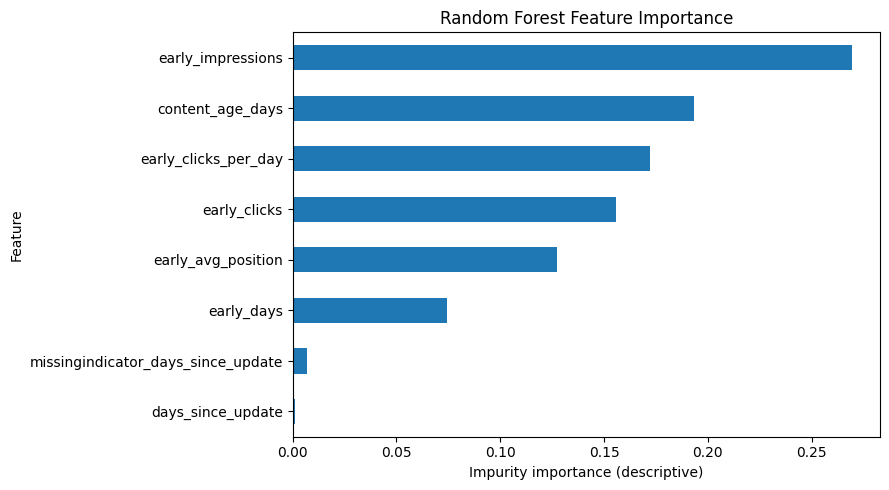

Saved held-out predictions and feature-importance figure.
Predictions: /content/FlyRank_Internship/work/outputs/w05_test_predictions.csv
Feature importance: /content/FlyRank_Internship/work/figures/w05_feature_importance.png


In [6]:

# 1. Prepare held-out test results
test_results = test[
    [GROUP, "content_hash_id", TARGET, "click_change_pct"]
].copy()

test_results["logistic_score"] = scores["Logistic Regression"]
test_results["forest_score"] = scores["Random Forest"]
test_results["baseline_score"] = scores["Week-4 rule baseline"]

# Predictions at the fixed 0.5 threshold (error analysis only)
test_results["logistic_pred_05"] = (
    test_results["logistic_score"] >= 0.5
).astype(int)

test_results["forest_pred_05"] = (
    test_results["forest_score"] >= 0.5
).astype(int)


# 2. Inspect false positives and false negatives
def error_examples(frame, pred_col, n=3):
    false_positives = (
        frame[(frame[TARGET] == 0) & (frame[pred_col] == 1)]
        .head(n)
        .assign(error="false positive")
    )

    false_negatives = (
        frame[(frame[TARGET] == 1) & (frame[pred_col] == 0)]
        .head(n)
        .assign(error="false negative")
    )

    return pd.concat(
        [false_positives, false_negatives],
        ignore_index=True
    )


print("Logistic Regression — Error Examples")
display(error_examples(test_results, "logistic_pred_05"))

print("Random Forest — Error Examples")
display(error_examples(test_results, "forest_pred_05"))


# 3. Random Forest feature importance
# The imputer adds missing-value indicator columns.
# Therefore, retrieve the actual transformed feature names.
rf_feature_names = forest.named_steps["imputer"].get_feature_names_out(
    FEATURES
)

rf_importance_values = forest.named_steps["model"].feature_importances_

assert len(rf_feature_names) == len(rf_importance_values), (
    "Feature names and importance values have different lengths."
)

rf_importance = pd.Series(
    rf_importance_values,
    index=rf_feature_names,
    name="importance"
).sort_values(ascending=False)

print("Random Forest Feature Importance")
display(
    rf_importance.to_frame(
        "random_forest_impurity_importance"
    )
)


# 4. Plot feature importance
ax = rf_importance.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Random Forest Feature Importance"
)

ax.set_xlabel("Impurity importance (descriptive)")
ax.set_ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "w05_feature_importance.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# 5. Export held-out predictions for Week 6 and Week 7
# Keep pseudonymous IDs and prediction outputs private.
predictions = test_results.copy()

predictions["baseline_rank_score"] = predictions["baseline_score"]

predictions.to_csv(
    OUTPUT_DIR / "w05_test_predictions.csv",
    index=False
)

print("Saved held-out predictions and feature-importance figure.")
print("Predictions:", OUTPUT_DIR / "w05_test_predictions.csv")
print("Feature importance:", FIGURE_DIR / "w05_feature_importance.png")


## 5. Self-check and conclusion

Do not write that the model is better unless the held-out comparison supports that claim. Compare each precision@K with the held-out base rate and the fixed rule. If the rule wins at one K and a model wins at another, report the trade-off rather than choosing the most flattering metric.

The notebook does not claim causality, does not use product flags or target-derived columns as features, and does not use client/content identifiers as model inputs.

In [7]:
assert train_clients.isdisjoint(test_clients)
assert set(FEATURES).isdisjoint({
    "click_change_pct","decline_label","late_clicks","late_impressions",
    "trend_pct","trend_direction","is_declining_label","health_score","priority_score"
})
assert comparison["base_rate"].nunique() == 1
assert len(comparison) == 3
assert (test_results["baseline_score"] == baseline_score(test).values).all()

receipt = {
    "lane":"Content-Day Performance / Decline Risk",
    "feature_window":[EARLY_START,EARLY_END],
    "outcome_window":[LATE_START,LATE_END],
    "split":"GroupShuffleSplit by client_hash_id",
    "random_seed":SEED,
    "train_rows":int(len(train)),
    "test_rows":int(len(test)),
    "train_clients":int(train[GROUP].nunique()),
    "test_clients":int(test[GROUP].nunique()),
    "test_base_rate":float(y_test.mean()),
    "features":FEATURES,
    "comparison":comparison.to_dict(orient="records"),
    "warning":"Single March within-month proxy evaluation; not a multi-month forward deployment test."
}
(OUTPUT_DIR / "w05_metrics.json").write_text(json.dumps(receipt,indent=2))
print("SELF-CHECK PASSED")
print("Metrics receipt:", OUTPUT_DIR / "w05_metrics.json")
print("Commit executed notebook, metrics JSON, and figure; keep prediction CSV local/private unless internship policy explicitly permits it.")

SELF-CHECK PASSED
Metrics receipt: /content/FlyRank_Internship/work/outputs/w05_metrics.json
Commit executed notebook, metrics JSON, and figure; keep prediction CSV local/private unless internship policy explicitly permits it.
